# 04 · Market features and the daily text–market panel

One row per **ticker × trading day t** (GME, AMC, BB; 2009–2023). Everything in a row is known by the **close of day t**; the `y_*` columns are outcomes of **day t+1**.

**Market features (day t).** log return, |return|, Parkinson range volatility `park = sqrt(ln(H/L)² / 4ln2)`, 5- and 20-day return volatility, abnormal log volume (vs previous 20 days), gaps to the 5/20/50-day moving averages, MA5/MA20 crossover.

**News features (FNSPID).** A headline dated D (date only) is used for trading day D+1 (`target_date` from 01), so it sits in the row of the trading day before that. Daily: count, sentiment = mean(p_bull − p_bear), clarity = mean|p_bull − p_bear|, ambiguity = normalised entropy of the mean distribution. Two versions: `nb_` = BiLSTM (03b), `nl_` = LLM teacher (03a).

**Reddit features (r/wallstreetbets, 2020–21).** Comment time converted to New York time; comments after the 16:00 close (or on non-trading days) go to the next trading day. Same metrics (`rd_`), plus upvote-weighted sentiment.

**QISS (Quantified Investor Sentiment Score).** x = sentiment × (1 − ambiguity) × log(1 + n), i.e. direction × conviction × attention, standardised per ticker with an **expanding, past-only** mean and sd. `qiss` = average of news and Reddit QISS where available.

**Targets (day t+1).** `y_log_park` (log range volatility), `y_abn_logvol` (abnormal log volume), `y_abs_ret`, `y_ret`, `y_above_ma20`.

**Sentiment model.** `SENT_VERSION` in the setup cell picks the BiLSTM scores: `v1` (03b) or `v2_reddit` (03d, rolling validation + Reddit labels, default).

**Output.** `DataSource/panel_daily_{SENT_VERSION}.csv` (and `panel_daily.csv` = latest)

In [2]:
# 0. Setup
from google.colab import drive
drive.mount('/content/drive')
import os, glob, numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

def find_project_dir(name="dl-quant_project"):
    cands = [f"/content/drive/MyDrive/Colab Notebooks/{name}", f"/content/drive/MyDrive/{name}",
             *glob.glob(f"/content/drive/MyDrive/*/{name}"), *glob.glob(f"/content/drive/Shareddrives/*/{name}")]
    for p in cands:
        if os.path.isdir(p): return p
    raise FileNotFoundError("Add a shortcut to the shared 'dl-quant_project' folder in My Drive (see 00_START_HERE).")
PROJECT_DIR = find_project_dir(); DATA_DIR = os.path.join(PROJECT_DIR, "DataSource")
pd.set_option("display.width", 200)
SENT_VERSION = "v2_reddit"   # "v1" = 03b BiLSTM; "v2_rolling" / "v2_reddit" = 03d BiLSTM
print("Data folder:", DATA_DIR, "| sentiment model:", SENT_VERSION)

Mounted at /content/drive
Data folder: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/DataSource | sentiment model: v2_reddit


## 1. Prices → market features and next-day targets

In [3]:
px = pd.read_csv(os.path.join(DATA_DIR, "prices_gme_amc_bb.csv"), header=[0, 1], index_col=0, skiprows=[2])
px.index = pd.to_datetime(px.index); px.index.name = "date"
P = px.stack(level=1, future_stack=True).reset_index().rename(columns={"level_1": "ticker", "Ticker": "ticker"})
P.columns = [c.lower().replace(" ", "_") for c in P.columns]
P = P.dropna(subset=["adj_close", "high", "low", "volume"]).query("volume > 0").sort_values(["ticker", "date"]).reset_index(drop=True)

def market_features(g):
    g = g.copy()
    g["ret"] = np.log(g.adj_close).diff()
    g["abs_ret"] = g.ret.abs()
    g["park"] = np.sqrt(np.log(g.high / g.low) ** 2 / (4 * np.log(2)))          # Parkinson daily range volatility
    g["log_park"] = np.log(g.park + 1e-4)
    g["vol_5"] = g.ret.rolling(5).std(); g["vol_20"] = g.ret.rolling(20).std()
    g["logvol"] = np.log(g.volume)
    g["abn_logvol"] = g.logvol - g.logvol.shift(1).rolling(20).mean()            # vs previous 20 days
    ma5, ma20, ma50 = (g.adj_close.rolling(k).mean() for k in (5, 20, 50))
    g["ma5_gap"] = g.adj_close / ma5 - 1; g["ma20_gap"] = g.adj_close / ma20 - 1; g["ma50_gap"] = g.adj_close / ma50 - 1
    g["ma5_20_cross"] = ma5 / ma20 - 1
    # next-day targets (known only after the close of t+1)
    g["y_log_park"] = g.log_park.shift(-1)
    g["y_abs_ret"] = g.abs_ret.shift(-1)
    g["y_abn_logvol"] = g.logvol.shift(-1) - g.logvol.rolling(20).mean()         # vs the 20 days up to t
    g["y_ret"] = g.ret.shift(-1)
    g["y_above_ma20"] = (g.adj_close.shift(-1) > ma20).astype(float).where(ma20.notna() & g.adj_close.shift(-1).notna())
    return g

P = pd.concat([market_features(g) for _, g in P.groupby("ticker")], ignore_index=True)
print(P.groupby("ticker").date.agg(["min", "max", "count"]))

              min        max  count
ticker                             
AMC    2013-12-18 2023-12-29   2525
BB     2009-01-02 2023-12-29   3774
GME    2009-01-02 2023-12-29   3774


## 2. News sentiment (BiLSTM and LLM) → daily

In [4]:
FN_FILE = "bilstm_scores_fnspid.csv" if SENT_VERSION == "v1" else f"bilstm_{SENT_VERSION}_scores_fnspid.csv"
B = pd.read_csv(os.path.join(DATA_DIR, FN_FILE), parse_dates=["date", "target_date"])
if SENT_VERSION != "v1": B = B.rename(columns={"b2_pbear": "b_pbear", "b2_pneu": "b_pneu", "b2_pbull": "b_pbull"})
days = {t: np.array(sorted(g.date.values)) for t, g in P.groupby("ticker")}

def row_day_for_target(ticker, target):
    # news dated D is used for target trading day T (from 01); it belongs to the info set of the trading day before T
    d = days[ticker]; pos = np.searchsorted(d, np.datetime64(target), side="left")
    return pd.Timestamp(d[pos - 1]) if 0 < pos <= len(d) else pd.NaT

B["day"] = [row_day_for_target(t, T) for t, T in zip(B.ticker, B.target_date)]
B = B.dropna(subset=["day"])

def text_agg(df, pb, pn, pu, prefix):
    s = df[pu] - df[pb]
    g = df.assign(_s=s, _c=s.abs()).groupby(["ticker", "day"])
    out = g.agg(**{f"{prefix}n": ("_s", "size"), f"{prefix}sent": ("_s", "mean"), f"{prefix}clar": ("_c", "mean"),
                   "_pb": (pb, "mean"), "_pn": (pn, "mean"), "_pu": (pu, "mean")})
    Pm = out[["_pb", "_pn", "_pu"]].to_numpy().clip(1e-9, 1)
    out[f"{prefix}amb"] = -(Pm * np.log(Pm)).sum(1) / np.log(3)
    return out.drop(columns=["_pb", "_pn", "_pu"]).reset_index().rename(columns={"day": "date"})

news_b = text_agg(B, "b_pbear", "b_pneu", "b_pbull", "nb_")      # BiLSTM
news_l = text_agg(B, "p_bear", "p_neu", "p_bull", "nl_")         # LLM teacher
print("news ticker-days:", len(news_b), "| articles mapped:", len(B))

news ticker-days: 3563 | articles mapped: 8776


## 3. Reddit sentiment (BiLSTM) → daily

In [5]:
Rr = pd.read_csv(os.path.join(DATA_DIR, "bilstm_scores_reddit.csv" if SENT_VERSION == "v1" else f"bilstm_{SENT_VERSION}_scores_reddit.csv"))
et = pd.to_datetime(Rr.created_utc, unit="s", utc=True).dt.tz_convert("America/New_York")
cand = et.dt.normalize().dt.tz_localize(None) + pd.to_timedelta((et.dt.hour >= 16).astype(int), unit="D")
Rr["day"] = pd.NaT
for t in Rr.ticker.unique():
    m = (Rr.ticker == t).to_numpy(); d = days[t]
    pos = np.searchsorted(d, cand[m].values.astype("datetime64[ns]"), side="left")
    ok = pos < len(d)
    vals = np.full(m.sum(), np.datetime64("NaT", "ns"), dtype="datetime64[ns]"); vals[ok] = d[pos[ok]]
    Rr.loc[m, "day"] = vals
Rr = Rr.dropna(subset=["day"]); Rr["day"] = pd.to_datetime(Rr.day)
red = text_agg(Rr, "p_bear", "p_neu", "p_bull", "rd_")
w = np.log1p(Rr.score.clip(lower=0)) + 1
Rr["_sw"] = (Rr.p_bull - Rr.p_bear) * w; Rr["_w"] = w
sw = Rr.groupby(["ticker", "day"]).agg(_sw=("_sw", "sum"), _w=("_w", "sum")).reset_index().rename(columns={"day": "date"})
sw["rd_sent_w"] = sw._sw / sw._w
red = red.merge(sw[["ticker", "date", "rd_sent_w"]], on=["ticker", "date"], how="left")
print("reddit ticker-days:", len(red)); print(red.groupby("ticker").agg(first=("date", "min"), last=("date", "max"), days=("date", "count"), comments=("rd_n", "sum")))

reddit ticker-days: 264
            first       last  days  comments
ticker                                      
AMC    2021-01-25 2021-07-06    93    296687
BB     2020-11-30 2021-06-21   103    176069
GME    2021-01-04 2021-04-12    68    440228


## 4. Merge, QISS, splits, save

In [6]:
D = P.merge(news_b, on=["ticker", "date"], how="left").merge(news_l, on=["ticker", "date"], how="left").merge(red, on=["ticker", "date"], how="left")
for p in ["nb_", "nl_", "rd_"]:
    D[f"{p}has"] = D[f"{p}n"].notna().astype(int)
    D[f"{p}n"] = D[f"{p}n"].fillna(0); D[f"{p}logn"] = np.log1p(D[f"{p}n"])
    D[[f"{p}sent", f"{p}clar"]] = D[[f"{p}sent", f"{p}clar"]].fillna(0.0)
    D[f"{p}amb"] = D[f"{p}amb"].fillna(1.0)          # no text = maximal ambiguity
D["rd_sent_w"] = D["rd_sent_w"].fillna(0.0)

def qiss(g, p, min_obs=60):
    x = g[f"{p}sent"] * (1 - g[f"{p}amb"]) * g[f"{p}logn"]                         # direction x conviction x attention
    mu = x.shift(1).expanding(min_obs).mean(); sd = x.shift(1).expanding(min_obs).std()   # past-only standardisation
    return ((x - mu) / sd).clip(-10, 10)

D = D.sort_values(["ticker", "date"]).reset_index(drop=True)
def by_ticker(fn):
    return pd.concat([fn(g) for _, g in D.groupby("ticker")]).reindex(D.index)
D["qiss_news"] = by_ticker(lambda g: qiss(g, "nb_"))
D["qiss_news_llm"] = by_ticker(lambda g: qiss(g, "nl_"))
D["qiss_reddit"] = by_ticker(lambda g: qiss(g[g.rd_has == 1], "rd_", min_obs=20))
D["qiss"] = D[["qiss_news", "qiss_reddit"]].mean(axis=1)
D["year"] = D.date.dt.year
D["split"] = np.select([D.year <= 2018, D.year <= 2020, D.year == 2021], ["train", "val", "test_2021"], "test_2022_23")
D.to_csv(os.path.join(DATA_DIR, f"panel_daily_{SENT_VERSION}.csv"), index=False)
D.to_csv(os.path.join(DATA_DIR, "panel_daily.csv"), index=False)            # latest version
print(D.shape); print(D.groupby(["ticker", "split"]).size().unstack())
print("ticker-days with news:", D.nb_has.sum(), "| with Reddit:", D.rd_has.sum())

(10073, 50)
split   test_2021  test_2022_23  train  val
ticker                                     
AMC           252           501   1267  505
BB            252           501   2516  505
GME           252           501   2516  505
ticker-days with news: 3563 | with Reddit: 264


## 5. Quick look: do the text features line up with next-day outcomes?
Spearman correlations (no model yet). Reddit rows only where Reddit was collected.

In [7]:
feats = ["nb_sent", "nb_clar", "nb_amb", "nb_logn", "qiss_news", "nl_sent", "qiss_news_llm", "rd_sent", "rd_sent_w", "rd_amb", "rd_logn", "qiss_reddit", "qiss"]
targets = ["y_ret", "y_log_park", "y_abn_logvol"]
out = []
for period, mask in [("2010-20", D.year.between(2010, 2020)), ("2021", D.year == 2021), ("2022-23", D.year >= 2022)]:
    sub = D[mask]
    for f in feats:
        s = sub[sub.rd_has == 1] if f.startswith("rd_") or f == "qiss_reddit" else sub
        for y in targets:
            z = s[[f, y]].dropna()
            if len(z) > 30:
                r, p = stats.spearmanr(z[f], z[y]); out.append({"feature": f, "period": period, "target": y, "rho": r, "p": p, "n": len(z)})
C = pd.DataFrame(out)
tab = C.assign(cell=lambda d: d.rho.round(3).astype(str) + np.where(d.p < 0.01, "**", np.where(d.p < 0.05, "*", "")))
print(tab.pivot_table(index="feature", columns=["target", "period"], values="cell", aggfunc="first").reindex(feats).to_string())
print("\n* p<0.05, ** p<0.01")
C.to_csv(os.path.join(DATA_DIR, f"panel_feature_correlations_{SENT_VERSION}.csv"), index=False)

target        y_abn_logvol                    y_log_park                      y_ret                
period             2010-20     2021   2022-23    2010-20     2021   2022-23 2010-20    2021 2022-23
feature                                                                                            
nb_sent             -0.009   0.14**     0.005   -0.043**    0.069  -0.071**   0.011   0.042   0.023
nb_clar            0.138**  0.162**   0.131**    0.125**  0.324**   0.307**  -0.005   0.067   -0.02
nb_amb            -0.118**    0.055  -0.076**   -0.093**   -0.037  -0.191**  -0.006  -0.005   0.024
nb_logn            0.153**  0.122**   0.144**     0.13**  0.522**   0.338**  -0.002   0.003   -0.03
qiss_news          -0.028*  0.103**     0.016     -0.008  0.126**   0.084**   0.018   0.027  -0.009
nl_sent             -0.004   0.19**      0.01   -0.046**    0.053   -0.064*   0.006   0.058   0.026
qiss_news_llm       -0.015  0.197**     0.028     0.08**  0.109**    0.13**   0.008    0.07   0.025


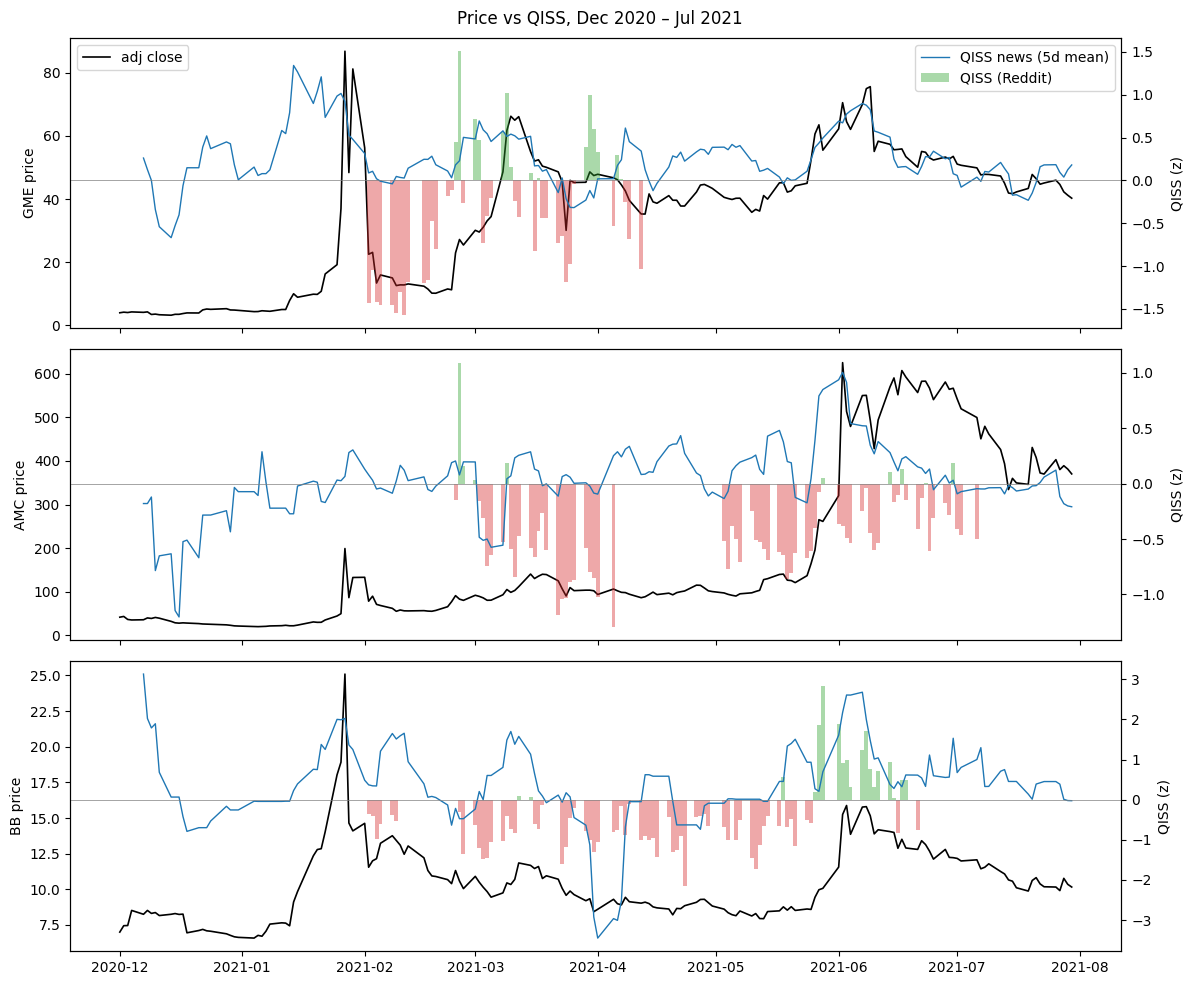

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, t in zip(axes, ["GME", "AMC", "BB"]):
    g = D[(D.ticker == t) & (D.date.between("2020-12-01", "2021-07-31"))]
    ax.plot(g.date, g.adj_close, color="black", lw=1.2, label="adj close")
    ax.set_ylabel(t + " price")
    ax2 = ax.twinx()
    ax2.bar(g.date, g.qiss_reddit.fillna(0), color=np.where(g.qiss_reddit.fillna(0) >= 0, "tab:green", "tab:red"), alpha=0.4, width=1, label="QISS (Reddit)")
    ax2.plot(g.date, g.qiss_news.fillna(0).rolling(5).mean(), color="tab:blue", lw=1, label="QISS news (5d mean)")
    ax2.set_ylabel("QISS (z)"); ax2.axhline(0, color="grey", lw=0.5)
    if t == "GME": ax2.legend(loc="upper right"); ax.legend(loc="upper left")
plt.suptitle("Price vs QISS, Dec 2020 – Jul 2021"); plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, f"fig_qiss_2021_{SENT_VERSION}.png"), dpi=120); plt.show()